# Taller práctico · IA aplicada a la catalogación bibliográfica


**Luis Roberto Polo Bautista** · Ignite Online



## Objetivo

Conocer una base práctica de IA, PNL y modelos de lenguaje que permita a los participantes experimentar, evaluar resultados y reconocer aplicaciones útiles en su trabajo cotidiano.


## Tokenizar

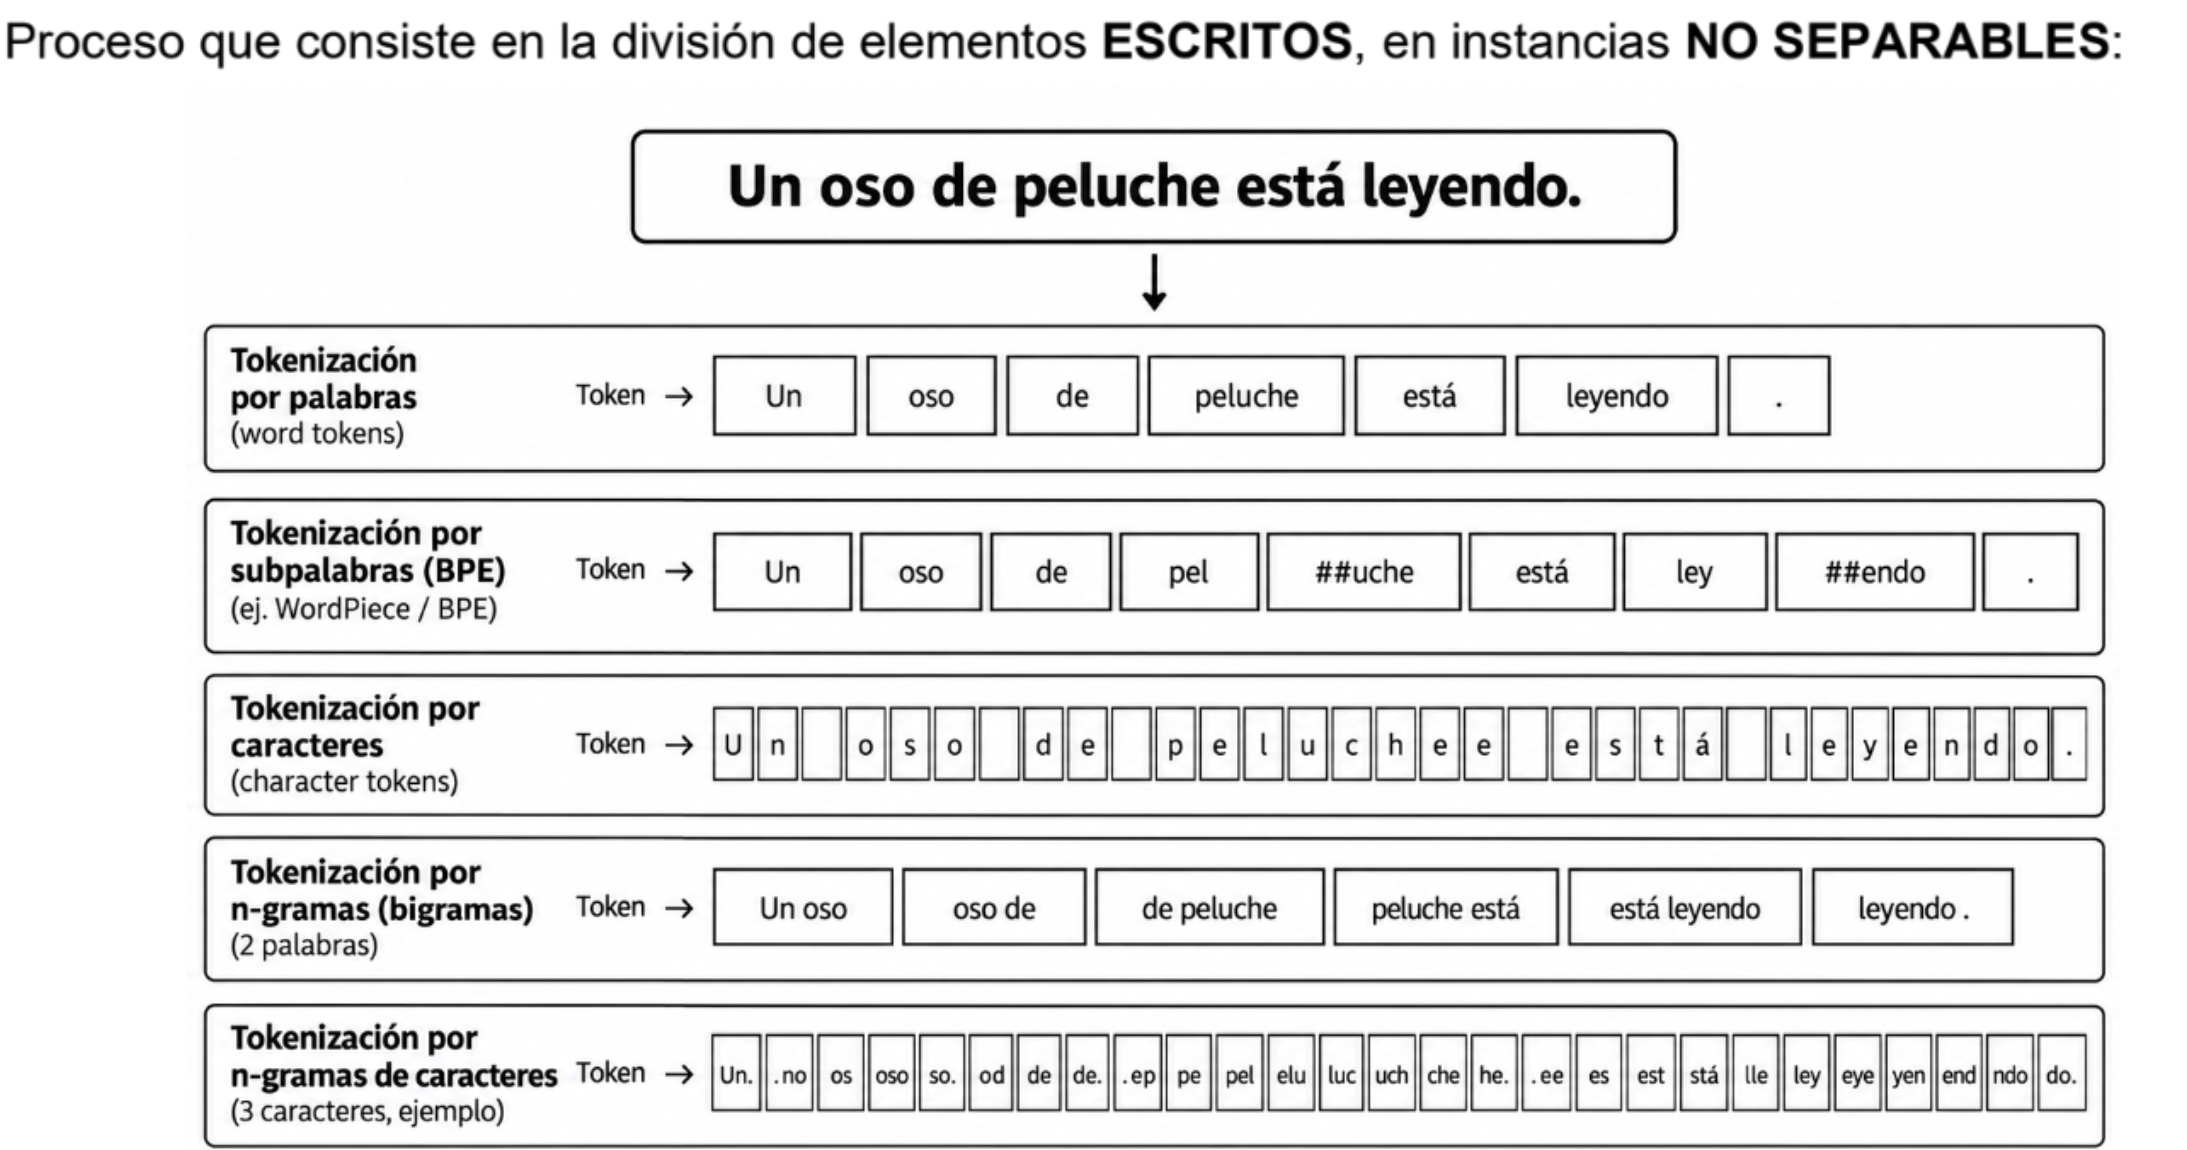



In [8]:

import re

texto = "Cien años de soledad, de Gabriel García Márquez."

# EJEMPLO 2: TÍTULO DE UN LIBRO
# texto = "La sombra del viento, de Carlos Ruiz Zafón"

# EJEMPLO 3: POEMA
# texto = """En el silencio habita una historia,
# cada palabra despierta memoria.
# Un libro abierto invita a soñar,
# mil universos por explorar."""

# EJEMPLO 4: CANCIÓN
# texto = """Cada mañana comienza un viaje,
# llevo mis sueños como equipaje.
# Entre caminos de luz y color,
# voy descubriendo un mundo mejor."""


# =====================================================
# PASO 2. TOKENIZACIÓN BÁSICA POR ESPACIOS
# =====================================================

tokens = texto.split()

print("\n=== 1. TOKENIZACIÓN POR ESPACIOS ===")
print("Texto original:", texto)

for numero, token in enumerate(tokens, start=1):
    print(numero, ":", token)

print("Total:", len(tokens))


# =====================================================
# PASO 3. TOKENIZACIÓN EN PALABRAS Y PUNTUACIÓN
# =====================================================

# Detectamos palabras y signos de puntuación
palabras = re.findall(r"\w+|[^\w\s]", texto)

print("\n=== 2. PALABRAS Y SIGNOS ===")

for numero, palabra in enumerate(palabras, start=1):
    print(numero, ":", palabra)

print("Total:", len(palabras))


# =====================================================
# PASO 4. EXPERIMENTO CON SUBPALABRAS
# =====================================================

# EXPERIMENTA CAMBIANDO ESTE VALOR:
# 2 = fragmentos más pequeños
# 4 = fragmentos medianos
# 6 = fragmentos más grandes

tamano = 6

print("\n=== SUBPALABRAS ===")

subpalabras = []

for palabra in texto.split():
    for i in range(0, len(palabra), tamano):
        fragmento = palabra[i:i + tamano]
        subpalabras.append(fragmento)
        print(fragmento)

print("Total:", len(subpalabras))


# =====================================================
# PASO 5. COMPARAR RESULTADOS
# =====================================================

print("\n=== COMPARACIÓN ===")

print("Tokens por espacios:", len(tokens))
print("Palabras y signos:", len(palabras))
print("Subpalabras:", len(subpalabras))




=== 1. TOKENIZACIÓN POR ESPACIOS ===
Texto original: Cien años de soledad, de Gabriel García Márquez.
1 : Cien
2 : años
3 : de
4 : soledad,
5 : de
6 : Gabriel
7 : García
8 : Márquez.
Total: 8

=== 2. PALABRAS Y SIGNOS ===
1 : Cien
2 : años
3 : de
4 : soledad
5 : ,
6 : de
7 : Gabriel
8 : García
9 : Márquez
10 : .
Total: 10

=== SUBPALABRAS ===
Cien
años
de
soleda
d,
de
Gabrie
l
García
Márque
z.
Total: 11

=== COMPARACIÓN ===
Tokens por espacios: 8
Palabras y signos: 10
Subpalabras: 11


## NER

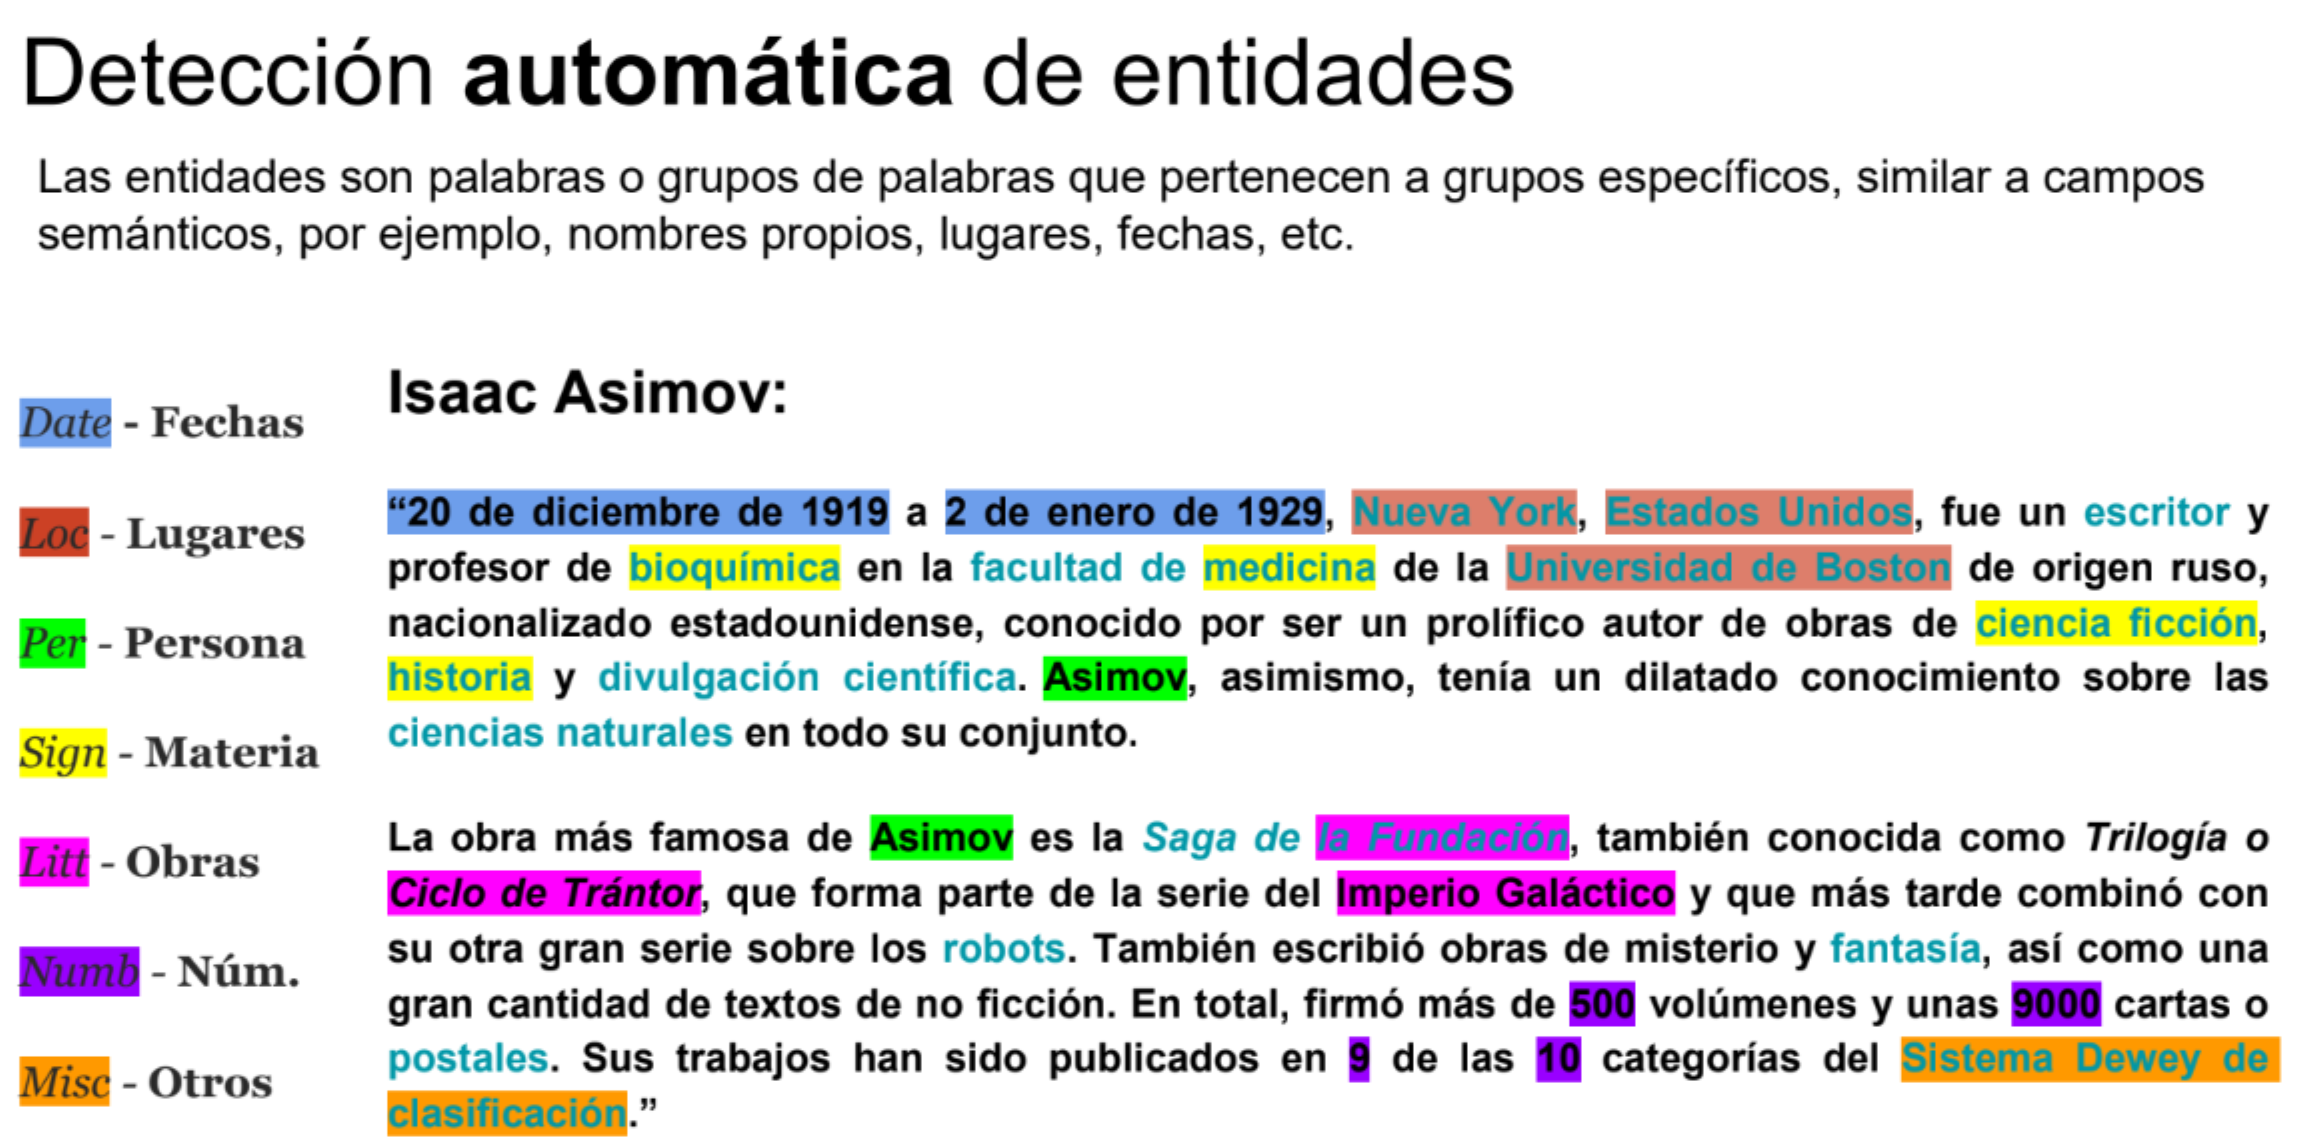

In [9]:

# Instalar spaCy y descargar su modelo en español
!pip -q install spacy
!python -m spacy download es_core_news_lg


#es_core_news_sm	12 MB
#es_core_news_md	40 MB
#es_core_news_lg	541 MB

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 568.0/568.0 MB 30.3 MB/s  0:00:12
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [10]:
import spacy

# Cargar el modelo de español
nlp = spacy.load("es_core_news_lg")

# Texto de ejemplo bibliográfico
texto = """
Gabriel García Márquez nació en Colombia.
Publicó Cien años de soledad en 1967.
La novela fue publicada por Editorial Sudamericana en Buenos Aires.
"""

#texto = """
#La Universidad Nacional Autónoma de México se encuentra en Ciudad de México.
#En 2024, la Biblioteca Nacional de México organizó un evento sobre inteligencia artificial.
#El proyecto contó con la participación de investigadores de España y Argentina.
#"""

# Procesar texto
documento = nlp(texto)

# Mostrar entidades identificadas
print("Entidades encontradas:\n")

for entidad in documento.ents:
    print(entidad.text, "→", entidad.label_)


Entidades encontradas:

Gabriel García Márquez → PER
Colombia → LOC
Cien años de soledad → MISC
La novela → MISC
Editorial Sudamericana → MISC
Buenos Aires → LOC


In [11]:

from spacy import displacy

# Visualizar las entidades encontradas
displacy.render(documento, style="ent", jupyter=True)

## Embeddings

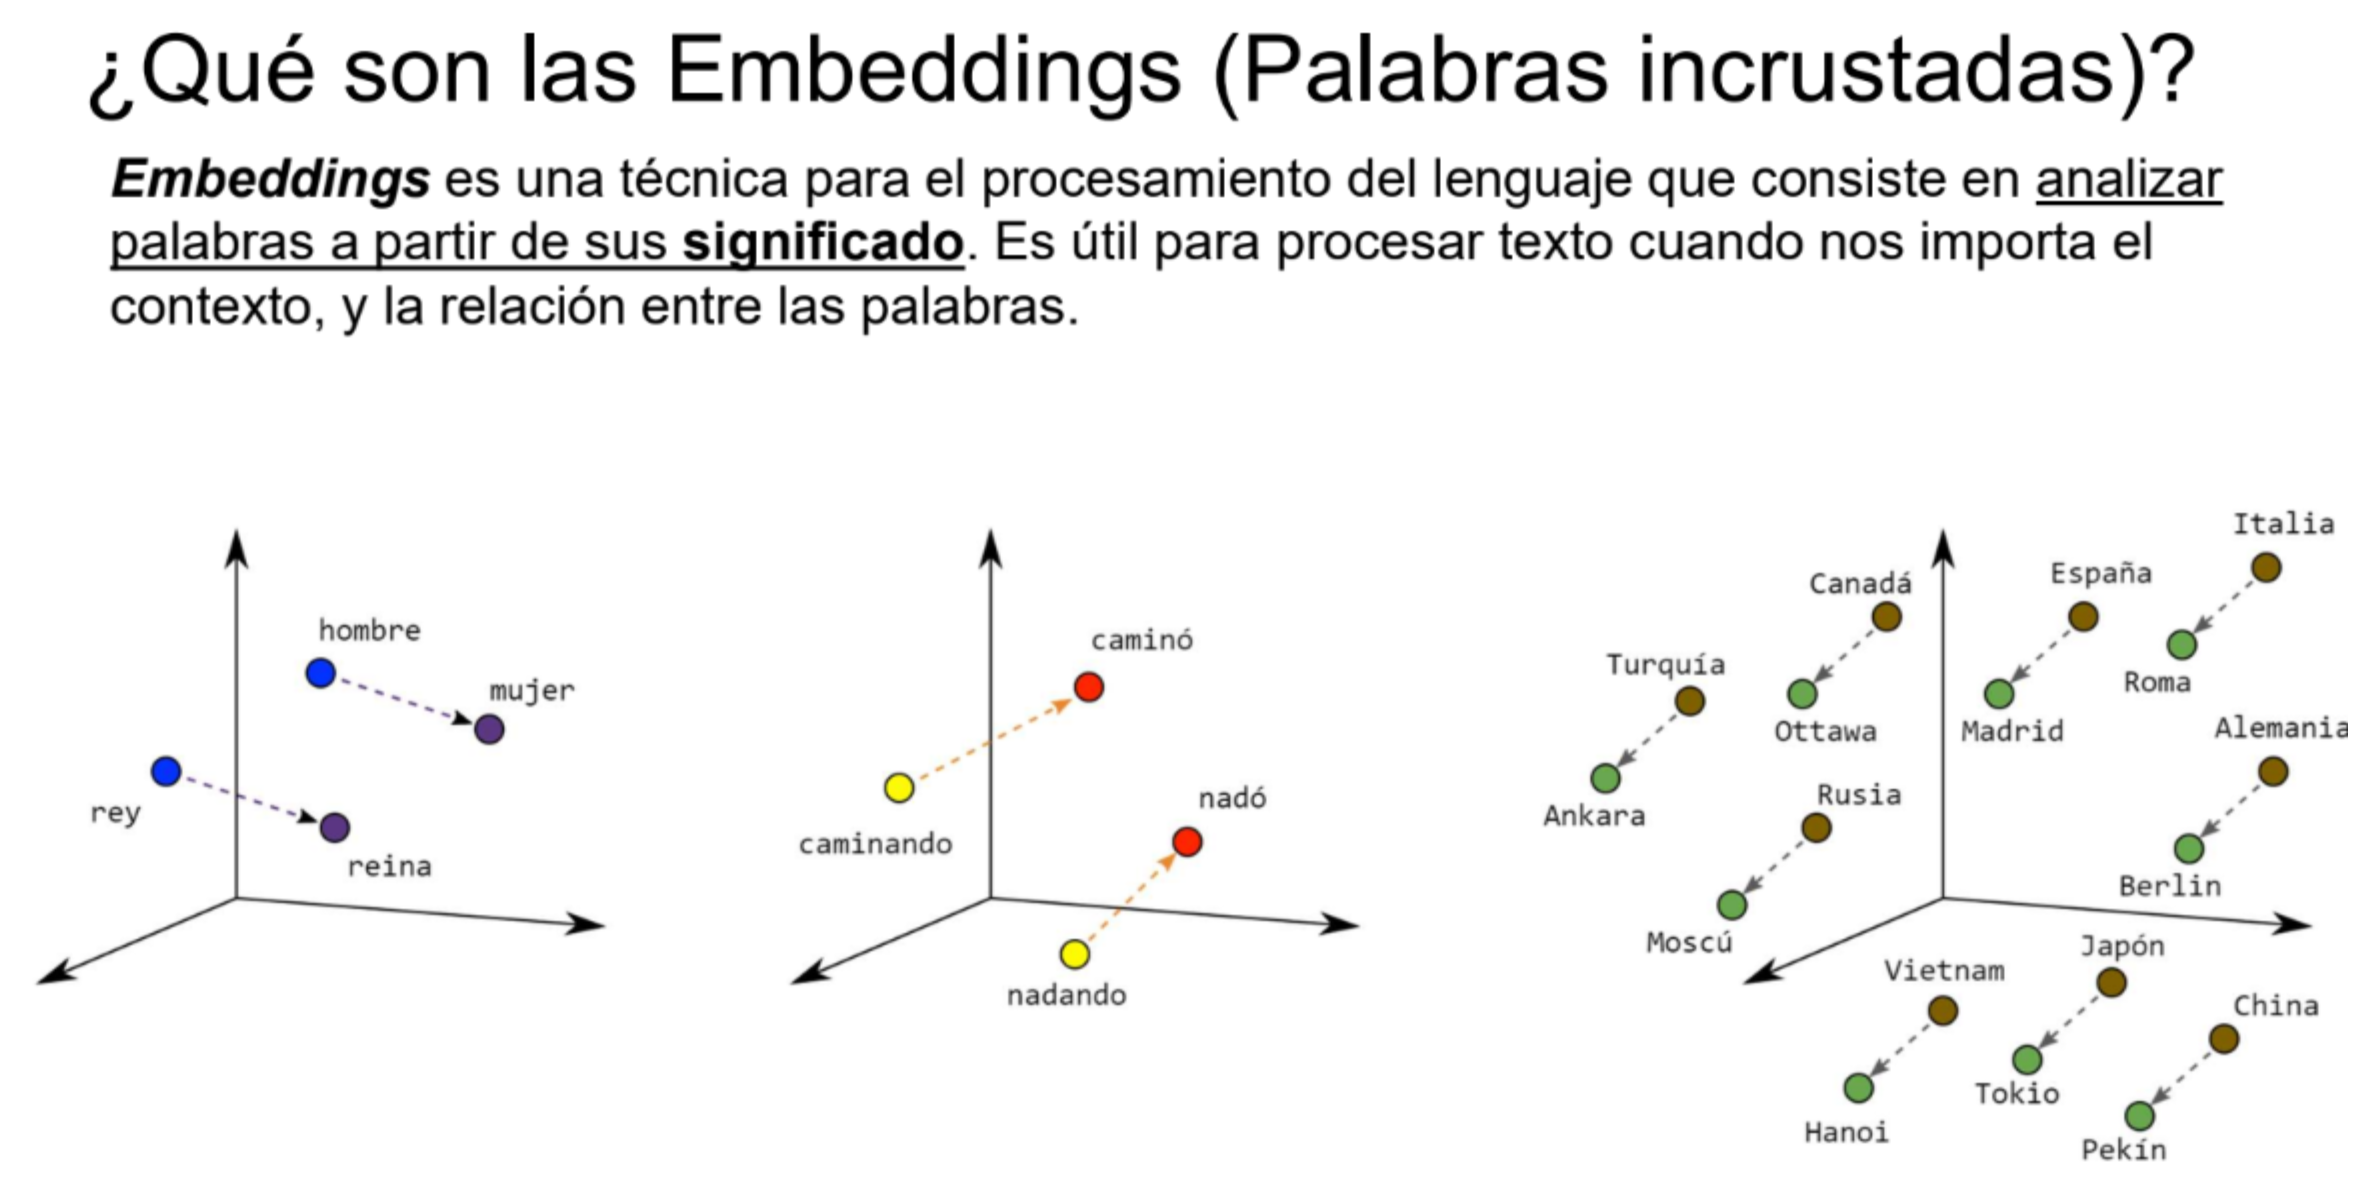

In [16]:

# Instalar biblioteca de embeddings
!pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Cargar modelo multilingüe
modelo = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

print("Modelo cargado correctamente")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo cargado correctamente


In [17]:

# TÍTULOS BIBLIOGRÁFICOS
titulos = [
    "Inteligencia artificial aplicada a bibliotecas",
    "Uso de modelos de lenguaje para catalogar libros",
    "Inteligencia artificial en bibliotecas universitarias",
    "Catalogación automática mediante aprendizaje profundo",
    "Gestión de colecciones digitales",
    "Cultivo sostenible de plantas medicinales",
    "El principito",
    "Cien años de soledad"
]

# Convertir los títulos en vectores numéricos
vectores = modelo.encode(titulos)

print("Primeros 30 valores del primer embedding:")
print(vectores[0][:10])

print("\nCantidad de títulos:", len(titulos))
print("Dimensiones de cada vector:", len(vectores[0]))


Primeros 30 valores del primer embedding:
[-0.34353673 -0.16885239 -0.42494363 -0.24332535 -0.14420344 -0.10883684
  0.01518286  0.00251776 -0.12505461  0.450281  ]

Cantidad de títulos: 8
Dimensiones de cada vector: 384


In [18]:

# Comparar semejanza entre todos los títulos
similitudes = cosine_similarity(vectores)

resultados = []

for i in range(len(titulos)):
    for j in range(i + 1, len(titulos)):
        resultados.append((
            similitudes[i][j],
            titulos[i],
            titulos[j]
        ))

# Ordenar de mayor a menor similitud
resultados.sort(reverse=True)

print("=== LOS 5 PARES MÁS SIMILARES ===\n")

for puntuacion, titulo1, titulo2 in resultados[:5]:
    print("Título 1:", titulo1)
    print("Título 2:", titulo2)
    print(f"Similitud: {puntuacion:.3f}")
    print("-----------------------------")


=== LOS 5 PARES MÁS SIMILARES ===

Título 1: Inteligencia artificial aplicada a bibliotecas
Título 2: Inteligencia artificial en bibliotecas universitarias
Similitud: 0.914
-----------------------------
Título 1: Uso de modelos de lenguaje para catalogar libros
Título 2: Catalogación automática mediante aprendizaje profundo
Similitud: 0.487
-----------------------------
Título 1: Inteligencia artificial aplicada a bibliotecas
Título 2: Gestión de colecciones digitales
Similitud: 0.477
-----------------------------
Título 1: Inteligencia artificial en bibliotecas universitarias
Título 2: Gestión de colecciones digitales
Similitud: 0.475
-----------------------------
Título 1: Inteligencia artificial aplicada a bibliotecas
Título 2: Catalogación automática mediante aprendizaje profundo
Similitud: 0.465
-----------------------------


##Regresar a presentación

##Prompt Engineering

**Zero-shot**: Se basa exclusivamente en la comprensión que el modelo ha adquirido durante su preentrenamiento para interpretar tu instrucción.
Funciona mejor para tareas comunes (resumen, traducción, clasificación básica).

**Few-shot**: Incluye de 2 a 5 ejemplos de entrada/salida en el *prompt* para mostrar el patrón exacto que deseas. Permite definir el formato, el tono y el manejo de casos excepcionales de manera más fiable que mediante el uso exclusivo de instrucciones.

**Cadena de pensamiento (CoT)**: Técnica que obliga a un modelo de inteligencia artificial a mostrar su proceso de razonamiento paso a paso antes de entregar una respuesta final


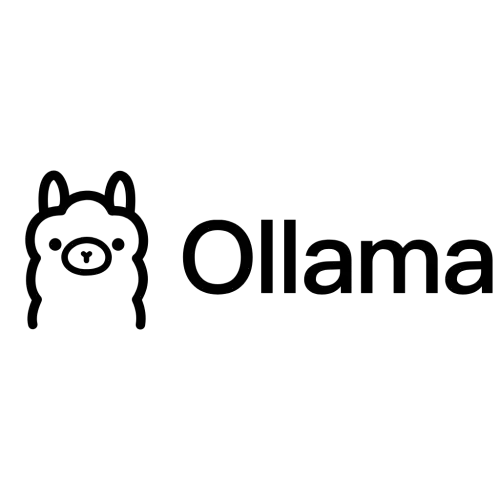



https://ollama.com/search

In [1]:

# Verificar GPU disponible
!nvidia-smi

Wed Oct 28 06:14:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

# Instalar dependencia
!apt-get update -qq
!apt-get install -y zstd

# Instalar Ollama
!curl -fsSL https://ollama.com/install.sh | sh


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 50 not upgraded.
Need to get 644 kB of archives.
After this operation, 1,845 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 zstd amd64 1.5.5+dfsg2-2build1.1 [644 kB]
Fetched 644 kB in 1s (533 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...
>>> Installing ollama to /usr/loca

In [21]:

import subprocess
import time
import requests

# Iniciar Ollama en segundo plano
log = open("/tmp/ollama-colab.log", "w")

servidor = subprocess.Popen(
    ["ollama", "serve"],
    stdout=log,
    stderr=subprocess.STDOUT
)

# Comprobar que el servidor responde
for intento in range(15):
    try:
        respuesta = requests.get(
            "http://127.0.0.1:11434/api/tags",
            timeout=3
        )
        if respuesta.status_code == 200:
            print("Servidor Ollama activo.")
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("No se pudo conectar con Ollama.")

# Descargar el modelo de lenguaje
subprocess.run(
    ["ollama", "pull", "llama3.2:3b"],
    check=True
)

print("Modelo llama3.2:3b preparado.")


Servidor Ollama activo.
Modelo llama3.2:3b preparado.


In [30]:

import requests

MODELO = "llama3.2:3b"

def consultar(prompt, temperatura=0):

    respuesta = requests.post(
        "http://127.0.0.1:11434/api/generate",
        json={
            "model": MODELO,
            "prompt": prompt,
            "stream": False,

            # Mantener el modelo cargado
            "keep_alive": "30m",

            "options": {
                "temperature": temperatura,

                # Máximo de tokens de respuesta
                "num_predict": 300,

                # Contexto reducido para ejercicios cortos
                "num_ctx": 2048
            }
        },
        timeout=180
    )

    respuesta.raise_for_status()
    datos = respuesta.json()

    print("Tiempo total:",
          round(datos["total_duration"] / 1e9, 2),
          "segundos")

    return datos["response"]

print("Modelo preparado para consultas")

Modelo preparado para consultas


In [31]:

# ZERO-SHOT PROMPTING
# El modelo debe clasificar sin recibir ejemplos.

prompt = """
porque el cielo es azul?.
"""

print(consultar(prompt))



Tiempo total: 3.99 segundos
**El misterio del cielo azul**

La pregunta "¿por qué el cielo es azul?" es una de las más antiguas y fascinantes de la historia de la humanidad. A lo largo de los siglos, los científicos y los filósofos han intentado explicar este fenómeno, pero la respuesta sigue siendo un tema de debate y investigación.

**La teoría clásica: la dispersión de la luz**

Hasta finales del siglo XIX, se creía que el cielo era azul debido a la presencia de un gas llamado "azurita" en la atmósfera. Sin embargo, esta teoría se desacreditó cuando se descubrió que la azurita no existía en la atmósfera.

En 1801, el científico inglés Thomas Young propuso una teoría alternativa: la dispersión de la luz. Según esta teoría, cuando la luz del sol pasa a través de la atmósfera, se dispersa en diferentes colores debido a la presencia de moléculas de gases como el nitrógeno y el oxígeno. El azul es el color que se dispersa más, lo que hace que el cielo aparezca azul.

**La explicación cie

In [24]:

# ¿Ollama está usando GPU o CPU?
!ollama ps

NAME           ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL               
llama3.2:3b    a80c4f17acd5    2.3 GB    100% GPU     2048       llamacpp    29 minutes from now    
llama3.2:1b    baf6a787fdff    1.4 GB    100% GPU     1024       llamacpp    26 minutes from now    


In [25]:
!nvidia-smi

Wed Oct 28 06:43:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P0             28W /   70W |    3815MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [32]:

# FEW-SHOT PROMPTING
# El modelo recibe ejemplos antes de clasificar.

prompt = """
Clasifica comentarios como POSITIVO,
NEGATIVO, NEUTRO.

Ejemplos:

Comentario: "La película fue excelente."
Clasificación: POSITIVO

Comentario: "El producto llegó roto."
Clasificación: NEGATIVO

Comentario: "La reunión comienza a las 10."
Clasificación: NEUTRO

Ahora clasifica:

Comentario: "El restaurante tiene buena comida,
pero el servicio fue lento."

Clasificación:
"""

print(consultar(prompt))


Tiempo total: 1.66 segundos
Comentario: "El restaurante tiene buena comida,
pero el servicio fue lento."

Clasificación: NEUTRO

Explicación: Aunque el comentario menciona que el restaurante tiene buena comida, que es un aspecto positivo, también menciona que el servicio fue lento, que es un aspecto negativo. La clasificación es NEUTRO porque el comentario no se centra únicamente en un aspecto positivo o negativo, sino que menciona ambos.


In [33]:

# CHAIN-OF-THOUGHT (CoT)
# Solución mediante pasos explícitos.

prompt = """
Una tienda tiene 20 camisetas.
Vende 7 por la mañana y recibe 5 nuevas
por la tarde.

¿Cuántas camisetas tiene al final?

Resuelve el problema mostrando cada uno de los puntos siguientes:

1. Cantidad inicial.
2. Cantidad después de vender.
3. Cantidad después de recibir.
4. Respuesta final.
"""

print(consultar(prompt))


Tiempo total: 2.13 segundos
¡Claro! Aquí te muestro los pasos para resolver el problema:

**1. Cantidad inicial**

La tienda tiene 20 camisetas al principio.

**2. Cantidad después de vender**

La tienda vende 7 camisetas por la mañana, por lo que la cantidad de camisetas que le quedan es:

20 - 7 = 13

**3. Cantidad después de recibir**

La tienda recibe 5 nuevas camisetas por la tarde, por lo que la cantidad de camisetas que le quedan es:

13 + 5 = 18

**4. Respuesta final**

La tienda tiene 18 camisetas al final.


##Regresar a la presentación

##IA en biblitecología

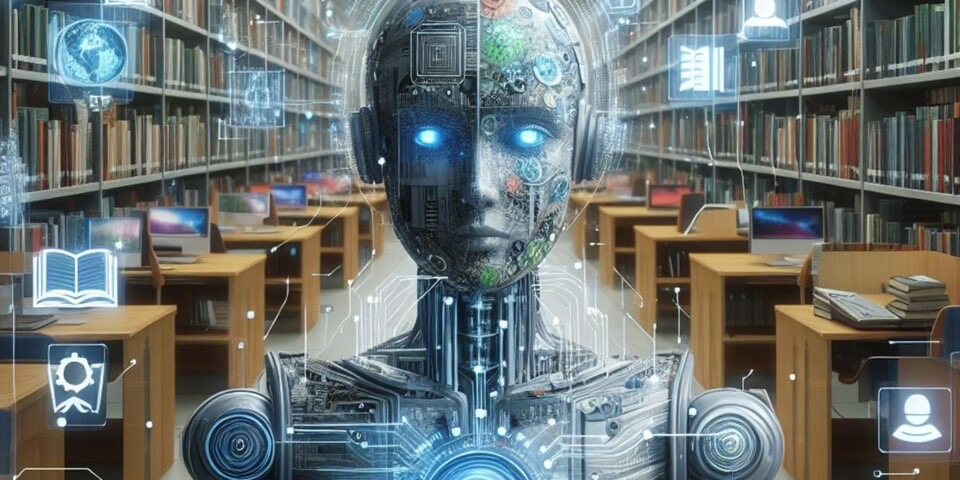

In [ ]:


# Mi primer chatbot

import re

# Definir las respuestas del chatbot basadas en patrones de expresiones regulares para una biblioteca
def regex_chatbot(entrada_usuario):
    # Definir patrones regex y respuestas correspondientes orientados a bibliotecas
    patrones = {
        r'(hola|buenos dias|buenas tardes|buenas noches|holi)': "¡Hola! Bienvenido a la biblioteca. ¿En qué te puedo ayudar hoy?",
        r'(horarios|hora de apertura|hora de cierre|abren|cierran)': "Nuestro horario de atención es de lunes a viernes de 9:00 AM a 8:00 PM, y sábados de 10:00 AM a 2:00 PM.",
        r'(libro|catalogo|buscar|encontrar|titulo|autor)': "Puedes buscar libros en nuestro catálogo en línea o consultar directamente en recepción con el título o autor.",
        r'(prestamo|prestar|llevar|sacar)': "Para solicitar un préstamo a domicilio necesitas tu credencial de socio vigente. Los préstamos duran 15 días renovables.",
        r'(devolucion|devolver|entregar|plazo)': "Las devoluciones se realizan en el mostrador principal o en el buzón de devoluciones fuera del horario de servicio.",
        r'(multa|retraso|cargo|pago)': "Las multas por retraso son de una pequeña tarifa por día de atraso y por libro. Debes liquidarlas en la caja de la biblioteca.",
        r'(credencial|socio|inscripcion|registro)': "Para hacerte socio y obtener tu credencial, solo necesitas una identificación oficial y un comprobante de domicilio reciente.",
        r'(gracias|muchas gracias|agradezco)': "¡De nada! Si tienes alguna otra duda sobre nuestros servicios, aquí estoy."
    }

    # Recorrer los patrones y buscar coincidencias en la entrada del usuario
    for patron, respuesta in patrones.items():
        if re.search(patron, entrada_usuario, re.IGNORECASE):
            return respuesta

    # Respuesta predeterminada si no se encuentra coincidencia
    return "Lo siento, no entendí tu consulta sobre la biblioteca. ¿Podrías reformular la pregunta?"

In [ ]:
print("¡Bienvenido a nuestra biblioteca! Escribe 'fin' para finalizar.")
while True:
    entrada_usuario = input("\nTú: ")
    if entrada_usuario.lower() == 'fin':
        print("Chatbot: Gracias por tu visita. ¡Hasta luego!")
        break
    respuesta = regex_chatbot(entrada_usuario)
    print(f"Chatbot: {respuesta}")

¡Bienvenido a nuestra biblioteca! Escribe 'fin' para finalizar.

Tú: hola
Chatbot: ¡Hola! Bienvenido a la biblioteca. ¿En qué te puedo ayudar hoy?

Tú: que puedo buscar
Chatbot: Puedes buscar libros en nuestro catálogo en línea o consultar directamente en recepción con el título o autor.

Tú: que horarios manejas
Chatbot: Nuestro horario de atención es de lunes a viernes de 9:00 AM a 8:00 PM, y sábados de 10:00 AM a 2:00 PM.

Tú: fin
Chatbot: Gracias por tu visita. ¡Hasta luego!


##4 ejecicios con IA y catalogación



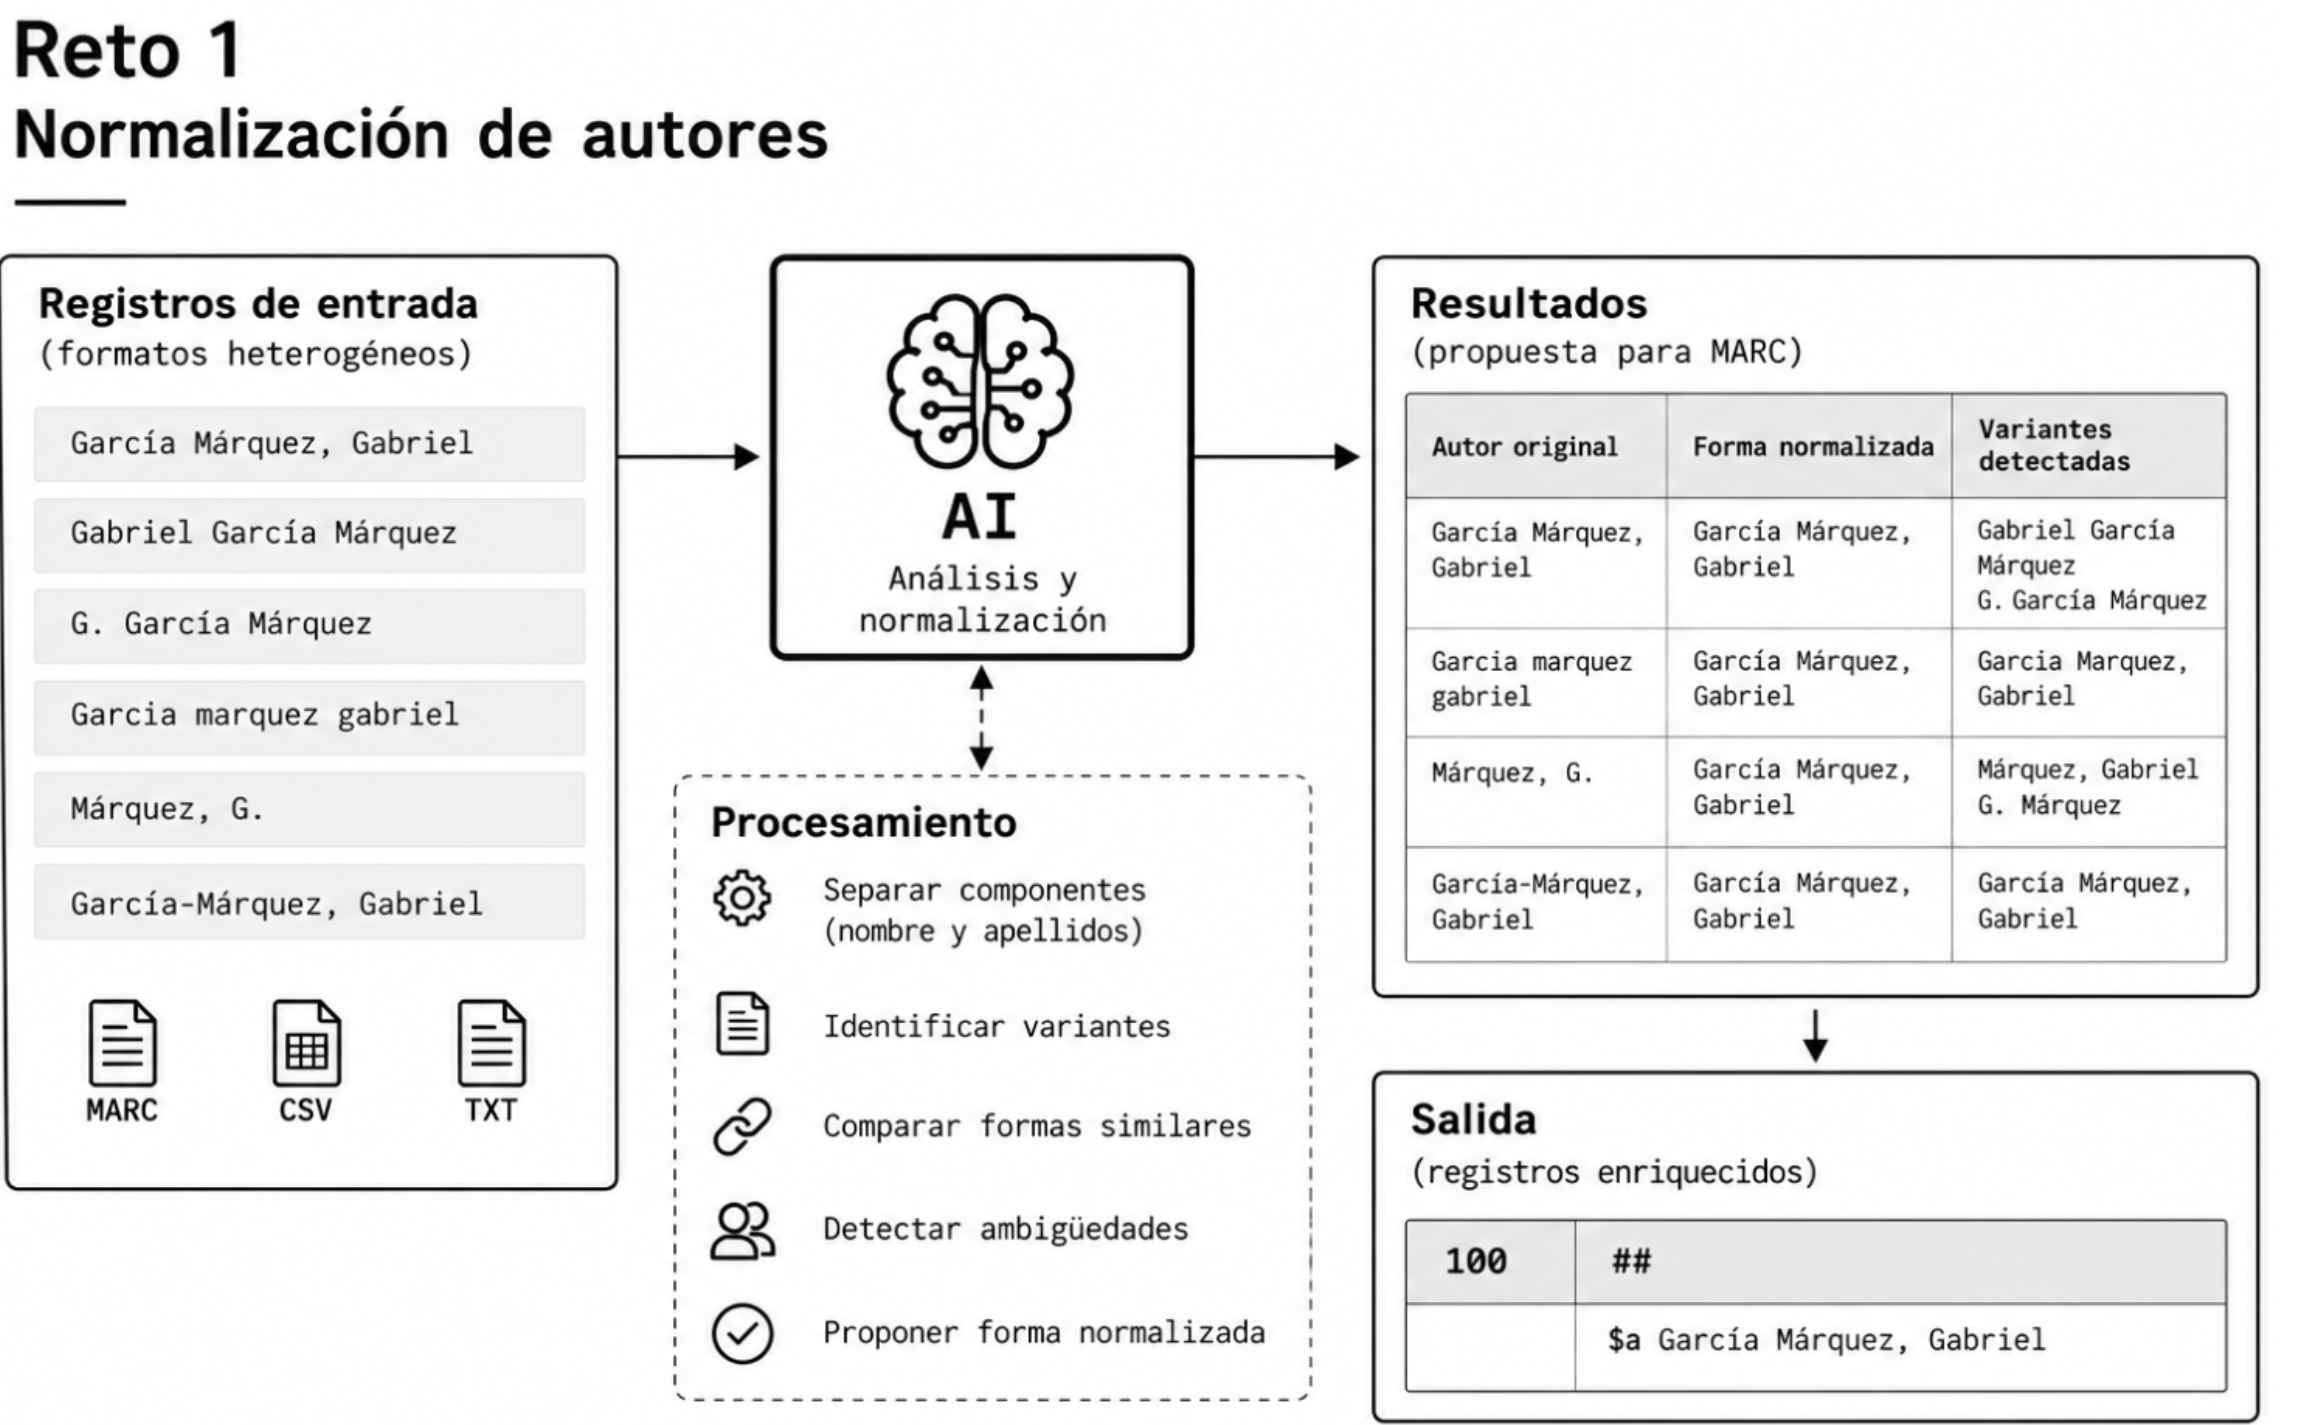

In [39]:

import pandas as pd
import requests
import json
from google.colab import files

# Importar Excel
def importar_excel():
    archivo = next(iter(files.upload()))
    return pd.read_excel(archivo)

df = importar_excel()

# Seleccionar solo los primeros 10 autores
autores = df.iloc[:10]["Autor"].tolist()

print(autores)


Saving Registros bibliográficos.xlsx to Registros bibliográficos (2).xlsx
['gabriel garcia marquez', 'ISABEL ALLENDE', 'Jorge Luis Borges', 'cortazar, julio', 'JUAN RULFO', 'vargas llosa, mario', 'Mario Benedetti', 'laura esquivel', 'OCTAVIO PAZ', 'roberto bolaño']


In [42]:

# Normalizar los 10 autores en una sola consulta
def normalizar(autores):

    prompt = (
        'Normaliza estos autores al formato "Apellidos, Nombres". '
        'La primera letra de cada nombre y apellido debe estar en MAYÚSCULA '
        'y las demás en minúscula. '
        'Ejemplo: "GABRIEL GARCIA MARQUEZ" → "García Márquez, Gabriel". '
        'Ejemplo: "ISABEL ALLENDE" → "Allende, Isabel". '
        'Corrige las tildes cuando corresponda. '
        'Devuelve solo JSON con una lista llamada "autores", '
        'en el mismo orden y cantidad:\n'
        + json.dumps(autores, ensure_ascii=False)
    )

    respuesta = requests.post(
        "http://127.0.0.1:11434/api/generate",
        json={
            "model": "llama3.2:3b",
            "prompt": prompt,
            "format": "json",
            "stream": False,
            "keep_alive": "30m",
            "options": {
                "temperature": 0.6,
                "num_predict": 300,
                "num_ctx": 1024
            }
        },
        timeout=180
    )

    respuesta.raise_for_status()
    return json.loads(respuesta.json()["response"])["autores"]


# Aplicar cambios solo a los primeros 10 registros
nuevos = normalizar(autores)

if len(nuevos) != len(autores):
    raise ValueError("Ollama no devolvió los 10 autores.")

df["Autor original"] = df["Autor"]
df.loc[df.index[:10], "Autor"] = nuevos

# Ver resultados
display(df.iloc[:10][["Autor original", "Autor"]])

# Descargar Excel corregido
#df.to_excel("registros_normalizados.xlsx", index=False)
#files.download("registros_normalizados.xlsx")


,Autor original,Autor
0,"GARCIA MARQUEZ, Gabriel","García Márquez, Gabriel"
1,"ALLENDE, Isabel","Allende, Isabel"
2,"BORES, Jorge Luis","Borges, Jorge Luis"
3,"CORTAZAR, Julio","Cortázar, Julio"
4,"RULFO, Juan","Rulfo, Juan"
5,"LLOSAS, Mario Vargas","Vargas Llosa, Mario"
6,"BENEDETTI, Mario","Benedetti, Mario"
7,"ESQUIVEL, Laura","Esquivel, Laura"
8,"PAZ, Octavio","Paz, Octavio"
9,"BOLAÑO, Roberto","Bolaño, Roberto"


**Actividad de evaluación**


¿El modelo conservó correctamente nombres y apellidos?

¿Identificó diferencias de mayúsculas y acentos?

¿Evitó completar iniciales sin evidencia?

¿Marcó los casos ambiguos para revisión?

¿Las propuestas podrían utilizarse después de una validación catalográfica?

# RETO 2 · Generación de resúmenes

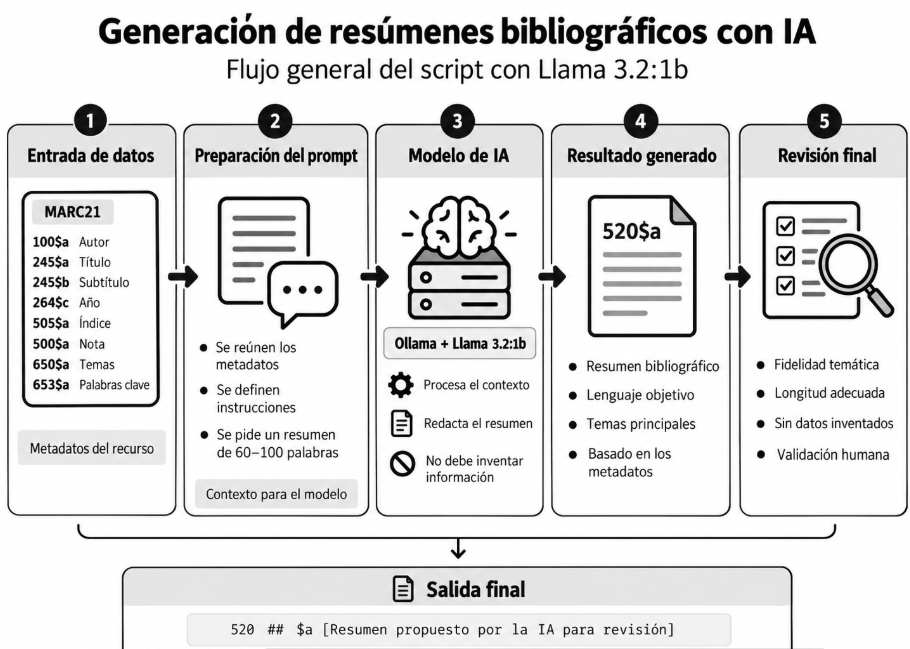

In [44]:

import pandas as pd
import requests
from google.colab import files

# Importar Excel
archivo = next(iter(files.upload()))
df = pd.read_excel(archivo)

# Seleccionar los primeros 10 registros
display(df.iloc[:10][["245$a", "505$a", "520$a"]])


Saving Ejercicio 2.xlsx to Ejercicio 2 (1).xlsx


,245$a,505$a,520$a
0,Preservación digital en bibliotecas,Fundamentos de preservación digital; riesgos t...,NaN
1,Inteligencia artificial en educación,Introducción a la inteligencia artificial; apr...,NaN
2,Archivos y memoria comunitaria,Archivos comunitarios; memoria colectiva e ide...,NaN
3,Catalogación y metadatos en entornos digitales,Descripción bibliográfica; estructura MARC21; ...,NaN
4,Acceso abierto y comunicación científica,Principios de acceso abierto; rutas de publica...,NaN
5,Bibliometría para bibliotecas académicas,Producción científica; citas e impacto; fuente...,NaN
6,Bibliotecas inclusivas y accesibilidad digital,Accesibilidad web; formatos alternativos; tecn...,NaN
7,Gestión de colecciones electrónicas,Selección de recursos; negociación de licencia...,NaN
8,Alfabetización informacional en la universidad,Búsqueda académica; evaluación de fuentes; cit...,NaN
9,Procesamiento del lenguaje natural para biblio...,Tokenización; lematización; reconocimiento de ...,NaN


In [46]:

# Cambia 10 por 3 si quieres hacer una prueba más corta
for i, registro in df.iloc[:10].iterrows():

    prompt = f"""
    Redacta un resumen bibliográfico de 60 a 80 palabras
    para el campo MARC21 520$a.

    Título: {registro['245$a']}
    Subtítulo: {registro['245$b']}
    Índice: {registro['505$a']}
    Temas: {registro['650$a']}
    Nota: {registro['500$a']}

    Usa solo esta información.
    No inventes contenido.
    Escribe en español, de forma objetiva.
    Devuelve únicamente el resumen.
    """

    respuesta = requests.post(
        "http://127.0.0.1:11434/api/generate",
        json={
            "model": "llama3.2:3b",
            "prompt": prompt,
            "stream": False,
            "keep_alive": "30m",
            "options": {
                "temperature": 0,
                "num_predict": 150,
                "num_ctx": 1024
            }
        },
        timeout=180
    )

    respuesta.raise_for_status()

    df.at[i, "520$a"] = respuesta.json()["response"].strip()
    print("Procesado:", registro["001"])

# Mostrar resultados
display(df.iloc[:10][["245$a", "520$a"]])

# Descargar Excel actualizado
#df.to_excel("resumenes_generados.xlsx", index=False)
#files.download("resumenes_generados.xlsx")


Procesado: B001
Procesado: B002
Procesado: B003
Procesado: B004
Procesado: B005
Procesado: B006
Procesado: B007
Procesado: B008
Procesado: B009
Procesado: B010


,245$a,520$a
0,Preservación digital en bibliotecas,"Resumen bibliográfico:\n\nLa obra ""Preservació..."
1,Inteligencia artificial en educación,Resumen bibliográfico:\n\nLa inteligencia arti...
2,Archivos y memoria comunitaria,"""Este estudio introductorio explora la organiz..."
3,Catalogación y metadatos en entornos digitales,"Resumen bibliográfico:\n\nLa guía ""Catalogació..."
4,Acceso abierto y comunicación científica,Resumen bibliográfico:\n\nEl acceso abierto y ...
5,Bibliometría para bibliotecas académicas,"Resumen bibliográfico para MARC21 520$a:\n\n""B..."
6,Bibliotecas inclusivas y accesibilidad digital,Resumen bibliográfico:\n\nLa biblioteca inclus...
7,Gestión de colecciones electrónicas,Resumen bibliográfico:\n\nLa gestión de colecc...
8,Alfabetización informacional en la universidad,Resumen bibliográfico:\n\nLa alfabetización in...
9,Procesamiento del lenguaje natural para biblio...,Resumen bibliográfico:\n\nEl campo MARC21 520$...


**Instrumento de autoevaluación**

Califica cada criterio de 1 (deficiente) a 5 (excelente).
1. Fidelidad a los metadatos originales


2. Cobertura de los temas principales


3. Ausencia de información inventada


4. Lenguaje objetivo y neutral


5. Extensión adecuada (60–100 palabras)


6. Claridad y coherencia


7. Utilidad para la recuperación temática


8. Adecuación al campo MARC21 520$a



Puntuación total
0 / 40

0 de 8 criterios evaluados. Una puntuación alta no sustituye la verificación de afirmaciones.

# RETO 3 · Puntos de acceso temáticos

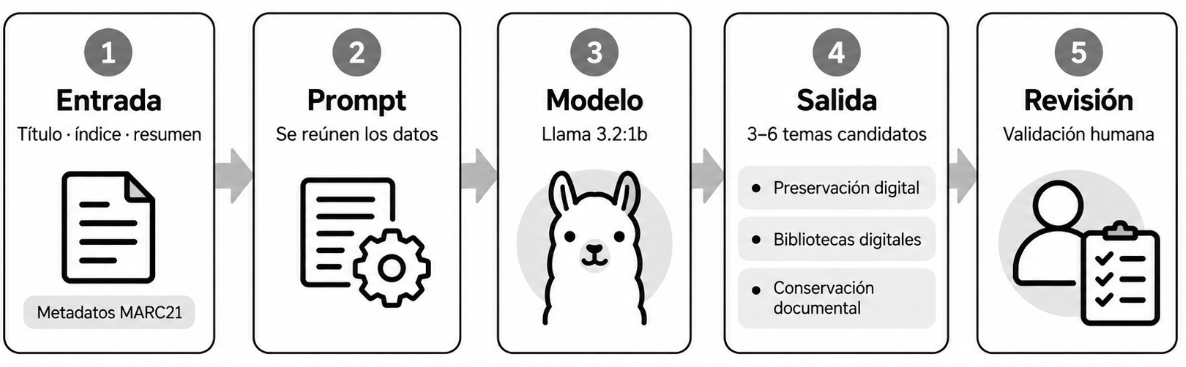

In [47]:

import pandas as pd
from google.colab import files

# Importar Excel
archivo = next(iter(files.upload()))
df = pd.read_excel(archivo).fillna("")

# Ver los primeros 10 registros
display(df.iloc[:10][["245$a", "505$a", "650$a"]])


Saving Ejercicio 3.xlsx to Ejercicio 3.xlsx


,245$a,505$a,650$a
0,Preservación digital en bibliotecas,Fundamentos de preservación digital; riesgos t...,
1,Inteligencia artificial en educación,Introducción a la inteligencia artificial; apr...,
2,Archivos y memoria comunitaria,Archivos comunitarios; memoria colectiva e ide...,
3,Catalogación y metadatos en entornos digitales,Descripción bibliográfica; estructura MARC21; ...,
4,Acceso abierto y comunicación científica,Principios de acceso abierto; rutas de publica...,
5,Bibliometría para bibliotecas académicas,Producción científica; citas e impacto; fuente...,
6,Bibliotecas inclusivas y accesibilidad digital,Accesibilidad web; formatos alternativos; tecn...,
7,Gestión de colecciones electrónicas,Selección de recursos; negociación de licencia...,
8,Alfabetización informacional en la universidad,Búsqueda académica; evaluación de fuentes; cit...,
9,Procesamiento del lenguaje natural para biblio...,Tokenización; lematización; reconocimiento de ...,


In [48]:

import requests
import json

# Cambia 10 por 3 para probar con menos registros
for i, registro in df.iloc[:10].iterrows():

    prompt = f"""
    Eres un asistente de catalogación bibliográfica.

    Propón entre 3 y 5 materias para MARC21 650$a.

    Título: {registro['245$a']}
    Subtítulo: {registro['245$b']}
    Índice: {registro['505$a']}
    Nota: {registro['500$a']}

    INSTRUCCIONES:
    - Usa términos breves en español.
    - Ordena los temas por relevancia.
    - Incluye temas generales y específicos.
    - No inventes información ni repitas términos.
    - No afirmes que son autoridades verificadas.
    - Devuelve solo JSON: {{"temas": ["Tema 1", "Tema 2", "Tema 3"]}}
    """

    respuesta = requests.post(
        "http://127.0.0.1:11434/api/generate",
        json={
            "model": "llama3.2:3b",
            "prompt": prompt,
            "format": "json",
            "stream": False,
            "keep_alive": "30m",
            "options": {
                "temperature": 0,
                "num_predict": 160,
                "num_ctx": 1024
            }
        },
        timeout=180
    )

    respuesta.raise_for_status()

    temas = json.loads(respuesta.json()["response"])["temas"]

    # Guardar las materias en el Excel
    df.at[i, "650$a"] = "; ".join(temas[:5])

    print("Procesado:", registro["245$a"])

# Mostrar resultados
display(df.iloc[:10][["245$a", "650$a"]])

# Descargar Excel actualizado
#df.to_excel("materias_generadas.xlsx", index=False)
#files.download("materias_generadas.xlsx")


Procesado: Preservación digital en bibliotecas
Procesado: Inteligencia artificial en educación
Procesado: Archivos y memoria comunitaria
Procesado: Catalogación y metadatos en entornos digitales
Procesado: Acceso abierto y comunicación científica
Procesado: Bibliometría para bibliotecas académicas
Procesado: Bibliotecas inclusivas y accesibilidad digital
Procesado: Gestión de colecciones electrónicas
Procesado: Alfabetización informacional en la universidad
Procesado: Procesamiento del lenguaje natural para bibliotecarios


,245$a,650$a
0,Preservación digital en bibliotecas,Formatos y obsolescencia digital; Copias de se...
1,Inteligencia artificial en educación,Aprendizaje automático; Inteligencia artificia...
2,Archivos y memoria comunitaria,Memoria colectiva e identidad cultural; Partic...
3,Catalogación y metadatos en entornos digitales,Control de calidad; Elementos RDA; Estructura ...
4,Acceso abierto y comunicación científica,Políticas de depósito; Repositorios institucio...
5,Bibliometría para bibliotecas académicas,Producción científica; Indicadores bibliométri...
6,Bibliotecas inclusivas y accesibilidad digital,Accesibilidad web; Formatos alternativos; Tecn...
7,Gestión de colecciones electrónicas,Selección de recursos; Negociación de licencia...
8,Alfabetización informacional en la universidad,Evaluación de fuentes; Búsqueda académica; Des...
9,Procesamiento del lenguaje natural para biblio...,Clasificación temática; Reconocimiento de enti...


**Instrumento de autoevaluación**

Evalúa cada criterio de 1 (deficiente) a 5 (excelente).

1. Pertinencia temática


2. Fidelidad a los metadatos


3. Orden de relevancia


4. Distinción entre temas amplios y específicos


5. Cobertura temática


6. Ausencia de redundancias


7. Cantidad de términos (3–6)


8. Posibilidad de validación con vocabulario controlado



Puntuación
0 / 40

0 de 8 criterios evaluados. La puntuación es orientativa y no equivale a una validación de autoridad.

# RETO 4 · Auditor de calidad de metadatos

**Entrada:** MARC21 con errores sembrados: resumen ausente, autor inconsistente, idioma dudoso, fecha incompatible, duplicación, materia genérica.

**Salida:** campo, problema, gravedad, explicación, acción sugerida.

**Control de calidad:** priorizar revisión humana; una anomalía es **indicio**, no prueba.

In [49]:

import pandas as pd
import requests
from google.colab import files

archivo = next(iter(files.upload()))
df = pd.read_csv(archivo, dtype=str).fillna("")

# Cambia 10 por 20 para auditar todos
N = 10
muestra = df.iloc[:N].copy()

display(muestra[["001", "100$a", "245$a", "650$a"]])

Saving Ejercicio 4.csv to Ejercicio 4.csv


,001,100$a,245$a,650$a
0,B001,"Martínez, Laura",Preservación digital en bibliotecas,Preservación digital; Bibliotecas digitales; C...
1,B002,CARLOS GOMEZ,Inteligencia artificial en educación,Educación; Inteligencia artificial
2,B003,"Torres, Gabriela",Archibos y memoria comunitaria,Archivos comunitarios; Historia oral
3,B004,"Ramírez, Elena",Datos abiertos para la investigación,Datos abiertos; Investigación científica
4,B005,"Vázquez, Norma",Literatura infantil contemporánea,Literatura infantil; Promoción de la lectura
5,B006,"Sánchez, Ana; López, Pedro",Introducción a la ciencia de datos,Ciencia; Tecnología
6,B007,"Ortega, Pablo",Metadatos para colecciones digitales,
7,B008,"Martínez, Laura",Preservación digital en bibliotecas,Preservación digital; Bibliotecas digitales
8,B009,"rojas, marta",Inteligensia artificial en archivos,Inteligencia artificial; Gestión documental
9,B010,"Pérez, Daniela",Gestión de bibliotecas universitarias,Bibliotecas universitarias; Gestión bibliotecaria


In [50]:

alertas = []

# Errores de ejemplo que queremos detectar
ortografia = ["archibos", "inteligensia",
              "catalogasión", "bibliotcas", "metadattos"]

for i, r in muestra.iterrows():

    problemas = []
    autor = r["100$a"]
    titulo = r["245$a"]

    if not titulo:
        problemas.append("Título vacío")

    if autor and "," not in autor:
        problemas.append("Autor sin normalizar")

    if ";" in autor:
        problemas.append("Varios autores en 100$a")

    if not r["520$a"]:
        problemas.append("Falta resumen")

    if not r["650$a"]:
        problemas.append("Faltan materias")

    if not r["300$a"]:
        problemas.append("Falta descripción física")

    if len(r["008"]) != 40:
        problemas.append("Campo 008 incompleto")
    elif (r["008"][7:11].isdigit()
          and r["264$c"].isdigit()
          and r["008"][7:11] != r["264$c"]):
        problemas.append("Años inconsistentes")

    if any(error in titulo.lower() for error in ortografia):
        problemas.append("Posible error ortográfico")

    if problemas:
        alertas.append({
            "001": r["001"],
            "Título": titulo,
            "Problemas": "; ".join(problemas)
        })

auditoria = pd.DataFrame(alertas)

display(auditoria)


,001,Título,Problemas
0,B002,Inteligencia artificial en educación,Autor sin normalizar; Falta resumen
1,B003,Archibos y memoria comunitaria,Falta descripción física; Posible error ortogr...
2,B004,Datos abiertos para la investigación,Años inconsistentes
3,B006,Introducción a la ciencia de datos,Varios autores en 100$a
4,B007,Metadatos para colecciones digitales,Falta resumen; Faltan materias
5,B009,Inteligensia artificial en archivos,Posible error ortográfico


In [51]:

acciones = []

for _, registro in auditoria.iterrows():

    prompt = f"""
    Eres auditor de registros MARC21.

    Título: {registro['Título']}
    Problemas: {registro['Problemas']}

    Sugiere cómo revisar estos errores.
    No inventes información.
    No modifiques el registro.
    Responde en máximo 35 palabras.
    """

    respuesta = requests.post(
        "http://127.0.0.1:11434/api/generate",
        json={
            "model": "llama3.2:1b",
            "prompt": prompt,
            "stream": False,
            "keep_alive": "30m",
            "options": {
                "temperature": 0,
                "num_predict": 70,
                "num_ctx": 1024
            }
        },
        timeout=180
    )

    respuesta.raise_for_status()
    acciones.append(respuesta.json()["response"].strip())

auditoria["Acción sugerida"] = acciones
auditoria["Estado"] = "PENDIENTE DE REVISIÓN"

display(auditoria)

# Descargar informe sin modificar el CSV original
auditoria.to_csv("informe_auditoria.csv", index=False,
                 encoding="utf-8-sig")
files.download("informe_auditoria.csv")


,001,Título,Problemas,Acción sugerida,Estado
0,B002,Inteligencia artificial en educación,Autor sin normalizar; Falta resumen,Revisar:\n\n- Verificar si el autor ha normali...,PENDIENTE DE REVISIÓN
1,B003,Archibos y memoria comunitaria,Falta descripción física; Posible error ortogr...,Revisaré los errores de descripción física y o...,PENDIENTE DE REVISIÓN
2,B004,Datos abiertos para la investigación,Años inconsistentes,Revisar los registros MARC21 por años inconsis...,PENDIENTE DE REVISIÓN
3,B006,Introducción a la ciencia de datos,Varios autores en 100$a,Revisar los errores en los siguientes pasos:\n...,PENDIENTE DE REVISIÓN
4,B007,Metadatos para colecciones digitales,Falta resumen; Faltan materias,Revisar los metadatos para colecciones digital...,PENDIENTE DE REVISIÓN
5,B009,Inteligensia artificial en archivos,Posible error ortográfico,Revisaré los errores de ortografía en la sigui...,PENDIENTE DE REVISIÓN


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Herramienta Ignite

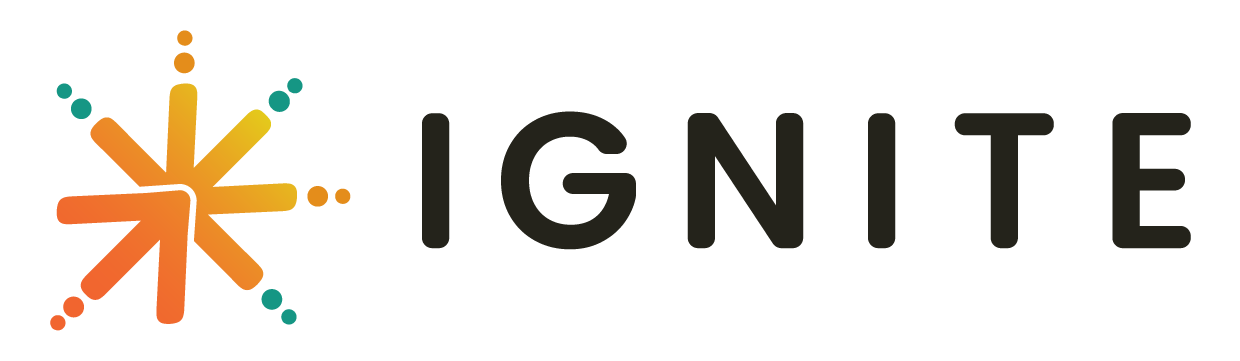